In [410]:
import numpy as np 
from scipy.linalg import ishermitian
import pandas as pd
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import HamiltonianGate, QFT, RYGate
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector
import matplotlib.pyplot as plt
import numpy as np
from scipy.linalg import expm, ishermitian
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit.library import UnitaryGate, QFT, RYGate
from qiskit.quantum_info import Statevector
from qiskit.circuit import QuantumCircuit
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.quantum_info import SparsePauliOp
from qiskit.circuit.library import CUGate
from qiskit.visualization import plot_histogram

In [411]:
# ===================================
#       Tratamento de Dados         #
# ===================================

train = pd.read_csv('mnist_train.csv')
test = pd.read_csv('mnist_test.csv')

print("Shape treino:", train.shape)
print("Shape teste:", test.shape)
print("\nPrimeiras colunas:", train.columns[:5].tolist())

Shape treino: (60000, 785)
Shape teste: (10000, 785)

Primeiras colunas: ['label', '1x1', '1x2', '1x3', '1x4']


In [412]:
test_69 = test[test['label'].isin([6, 9])].reset_index(drop=True)
train_69 = train[train['label'].isin([6, 9])].reset_index(drop=True)

print("Imagens de teste com 6 e 9:", len(test_69))
print("Imagens de treino com 6 e 9:", len(train_69))
print("\nDistribuição no teste:")
print(test_69['label'].value_counts())

Imagens de teste com 6 e 9: 1967
Imagens de treino com 6 e 9: 11867

Distribuição no teste:
label
9    1009
6     958
Name: count, dtype: int64


In [ ]:
def calcular_hr_vr(pixels_flat):
    img = pixels_flat.reshape(28, 28)

    metade_esq = img[:, :14] 
    metade_dir = img[:, 14:]   
    metade_sup = img[:14, :]   
    metade_inf = img[14:, :]   
    
    soma_esq = metade_esq.sum()
    soma_dir = metade_dir.sum()
    soma_sup = metade_sup.sum()
    soma_inf = metade_inf.sum()
    
    HR = soma_esq / soma_dir if soma_dir > 0 else 0       
    VR = soma_sup / soma_inf if soma_inf > 0 else 0
    
    return HR, VR

In [414]:
treino_6 = train_69[train_69['label'] == 6].reset_index(drop=True)
treino_9 = train_69[train_69['label'] == 9].reset_index(drop=True)

#print(treino_6)

print(f"Imagens de treino com 6: {len(treino_6)}")
print(f"Imagens de treino com 9: {len(treino_9)}")


Imagens de treino com 6: 5918
Imagens de treino com 9: 5949


In [415]:
resultados_6 = []
for i in range(len(treino_6)):
    pixels = treino_6.iloc[i, 1:].values
    HR, VR = calcular_hr_vr(pixels)
    resultados_6.append({'HR': HR, 'VR': VR})

resultados_9 = []
for i in range(len(treino_9)):
    pixels = treino_9.iloc[i, 1:].values
    HR, VR = calcular_hr_vr(pixels)
    resultados_9.append({'HR': HR, 'VR': VR})

    df_treino_6 = pd.DataFrame(resultados_6)
df_treino_9 = pd.DataFrame(resultados_9)

HR_medio_6 = df_treino_6['HR'].mean()
VR_medio_6 = df_treino_6['VR'].mean()
HR_medio_9 = df_treino_9['HR'].mean()
VR_medio_9 = df_treino_9['VR'].mean()

print(f"\nPonto médio do 6: HR={HR_medio_6:.4f}, VR={VR_medio_6:.4f}")
print(f"Ponto médio do 9: HR={HR_medio_9:.4f}, VR={VR_medio_9:.4f}")


Ponto médio do 6: HR=0.9326, VR=0.6640
Ponto médio do 9: HR=0.7299, VR=1.0049


In [416]:
x0_raw = np.array([HR_medio_6, VR_medio_6])
x1_raw = np.array([HR_medio_9, VR_medio_9])

x0 = x0_raw / np.linalg.norm(x0_raw)
x1 = x1_raw / np.linalg.norm(x1_raw)

print(f"Ponto treino 6 ({x0_raw[0]:.4f}, {x0_raw[1]:.4f})")
print(f"Ponto treino 6 normalizado ({x0[0]:.4f}, {x0[1]:.4f})") 
print(f"Ponto treino 9 ({x1_raw[0]:.4f}, {x1_raw[1]:.4f})")
print(f"Ponto treino 9 normalizado ({x1[0]:.4f}, {x1[1]:.4f})")   

Ponto treino 6 (0.9326, 0.6640)
Ponto treino 6 normalizado (0.8146, 0.5800)
Ponto treino 9 (0.7299, 1.0049)
Ponto treino 9 normalizado (0.5877, 0.8091)


In [417]:
df_teste = []

for _, row in test_69.iterrows():
    pixels = row.iloc[1:].to_numpy()
    HR, VR = calcular_hr_vr(pixels)
    y_real = 1 if row['label'] == 6 else -1

    df_teste.append({
        'HR': HR,
        'VR': VR,
        'y_real': y_real
    })

df_teste = pd.DataFrame(df_teste)

In [418]:
# --------------------------------------------
# 1. Matriz K
# --------------------------------------------

K = np.array([
    [np.dot(x0, x0), np.dot(x0, x1)],
    [np.dot(x1, x0), np.dot(x1, x1)]
])

print("K =")
print(K)

# --------------------------------------------
# 2. Matriz regularizada A
# --------------------------------------------

gamma = 1.0

A = K + gamma * np.eye(K.shape[0])
A = 0.5 * (A + A.T)

print("\nA =")
print(A)

# --------------------------------------------
# 3. Normalização espectral
# --------------------------------------------

eigvals_A = np.linalg.eigvalsh(A)

if np.any(eigvals_A <= 0):
    raise ValueError("A matriz A não é definida positiva.")

lambda_max = eigvals_A[-1]
lambda_min = eigvals_A[0]

# gamma já fornece a regularização principal
mu = 0.0

A_reg = A + mu * np.eye(A.shape[0])
A_hat = A_reg / lambda_max

print("\nA_hat =")
print(A_hat)

# Autovalores da matriz normalizada
eigvals_hat = np.linalg.eigvalsh(A_hat)

lambda_min_hat = eigvals_hat[0]
lambda_max_hat = eigvals_hat[-1]

print("\nAutovalores de A_hat:")
print(eigvals_hat)
print(f"\nlambda_min_hat = {lambda_min_hat:.9f}")
print(f"lambda_max_hat = {lambda_max_hat:.9f}")

# Número de condição
cond_hat = lambda_max_hat / lambda_min_hat
print(f"cond(A_hat) = {cond_hat:.6f}")

# --------------------------------------------
# 4. Normalização do vetor y
# --------------------------------------------

y = np.array([1.0, -1.0])
y_hat = y / np.linalg.norm(y)

print("\n|y> =")
print(y_hat)

# --------------------------------------------
# 5. Número de qubits
# --------------------------------------------

N = A.shape[0]
n_data = int(np.ceil(np.log2(N)))

m_phase = 3
resolution = 2 ** m_phase

print("\nDimensão da matriz N =", N)
print("Qubits de dados =", n_data)
print("Qubits de fase =", m_phase)
print("Resolução de fase =", resolution)

# --------------------------------------------
# 6. Teste de valores para t
# --------------------------------------------

t_referencia = np.pi / (2 * lambda_min_hat)

print(f"\nt de referência = {t_referencia:.6f}")

t_valores = [2.5, 3.5, 4.4, 5.0]

for t_test in t_valores:
    phi_min = lambda_min_hat * t_test / (2 * np.pi)
    phi_max = lambda_max_hat * t_test / (2 * np.pi)

    print("\n--------------------------------------------")
    print(f"t = {t_test}")
    print(f"phi_min = {phi_min:.6f}")
    print(f"phi_max = {phi_max:.6f}")
    print(f"phi_min * {resolution} = {phi_min * resolution:.6f}")
    print(f"phi_max * {resolution} = {phi_max * resolution:.6f}")

# --------------------------------------------
# 7. Avaliação da discretização das fases
# --------------------------------------------

t_valores = [2.5, 3.5, 4.4, 5.0]

resultados_t = []

for t_test in t_valores:
    phi_min = lambda_min_hat * t_test / (2 * np.pi)
    phi_max = lambda_max_hat * t_test / (2 * np.pi)

    fase_min_discreta = round(phi_min * resolution) / resolution
    fase_max_discreta = round(phi_max * resolution) / resolution

    erro_min = abs(phi_min - fase_min_discreta)
    erro_max = abs(phi_max - fase_max_discreta)

    resultados_t.append({
        "t": t_test,
        "phi_min": phi_min,
        "phi_max": phi_max,
        "fase_min_discreta": fase_min_discreta,
        "erro_min": erro_min,
        "fase_max_discreta": fase_max_discreta,
        "erro_max": erro_max
    })

df_t = pd.DataFrame(resultados_t)
print(df_t)

# Escolha baseada no erro da fase do autovalor relevante
melhor_t = df_t.loc[df_t["erro_min"].idxmin(), "t"]
print(f"\nMelhor t entre os candidatos = {melhor_t}") 


# --------------------------------------------
# 8. Escolha de t pela discretização da fase
# --------------------------------------------

t_hhl = 4.4

# O vetor |y> é o autovetor associado a lambda_min_hat
phi_y = lambda_min_hat * t_hhl / (2 * np.pi)

indice_fase = round(phi_y * resolution)
fase_discreta = indice_fase / resolution
erro_fase = abs(phi_y - fase_discreta)

print("t escolhido =", t_hhl)
print("Autovalor associado a |y> =", lambda_min_hat)
print("Fase exata =", phi_y)
print("Índice discreto =", indice_fase)
print("Fase discreta =", fase_discreta)
print("Erro de discretização =", erro_fase)
print("Representação binária =", format(indice_fase, f"0{m_phase}b"))

K =
[[1.         0.94802323]
 [0.94802323 1.        ]]

A =
[[2.         0.94802323]
 [0.94802323 2.        ]]

A_hat =
[[0.67842071 0.32157929]
 [0.32157929 0.67842071]]

Autovalores de A_hat:
[0.35684141 1.        ]

lambda_min_hat = 0.356841411
lambda_max_hat = 1.000000000
cond(A_hat) = 2.802365

|y> =
[ 0.70710678 -0.70710678]

Dimensão da matriz N = 2
Qubits de dados = 1
Qubits de fase = 3
Resolução de fase = 8

t de referência = 4.401945

--------------------------------------------
t = 2.5
phi_min = 0.141983
phi_max = 0.397887
phi_min * 8 = 1.135861
phi_max * 8 = 3.183099

--------------------------------------------
t = 3.5
phi_min = 0.198776
phi_max = 0.557042
phi_min * 8 = 1.590206
phi_max * 8 = 4.456338

--------------------------------------------
t = 4.4
phi_min = 0.249890
phi_max = 0.700282
phi_min * 8 = 1.999116
phi_max * 8 = 5.602254

--------------------------------------------
t = 5.0
phi_min = 0.283965
phi_max = 0.795775
phi_min * 8 = 2.271723
phi_max * 8 = 6.366198


In [419]:
# --------------------------------------------
# 9. Escolha de t pela discretização da fase
# --------------------------------------------

df_teste = []

for _, row in test_69.iterrows():
    pixels = row.iloc[1:].to_numpy()
    HR, VR = calcular_hr_vr(pixels)
    y_real = 1 if row['label'] == 6 else -1
    
    df_teste.append({
        'HR': HR,
        'VR': VR,
        'y_real': y_real
    })

df_teste = pd.DataFrame(df_teste)
print(df_teste)

            HR        VR  y_real
0     0.839315  0.986232      -1
1     0.890262  1.012453      -1
2     1.245931  0.845801       1
3     0.602788  0.873813      -1
4     0.611821  0.823249      -1
...        ...       ...     ...
1962  0.816192  0.655502       1
1963  0.855521  0.569748       1
1964  0.940844  0.537401       1
1965  0.686716  0.797253      -1
1966  0.922649  0.637812       1

[1967 rows x 3 columns]


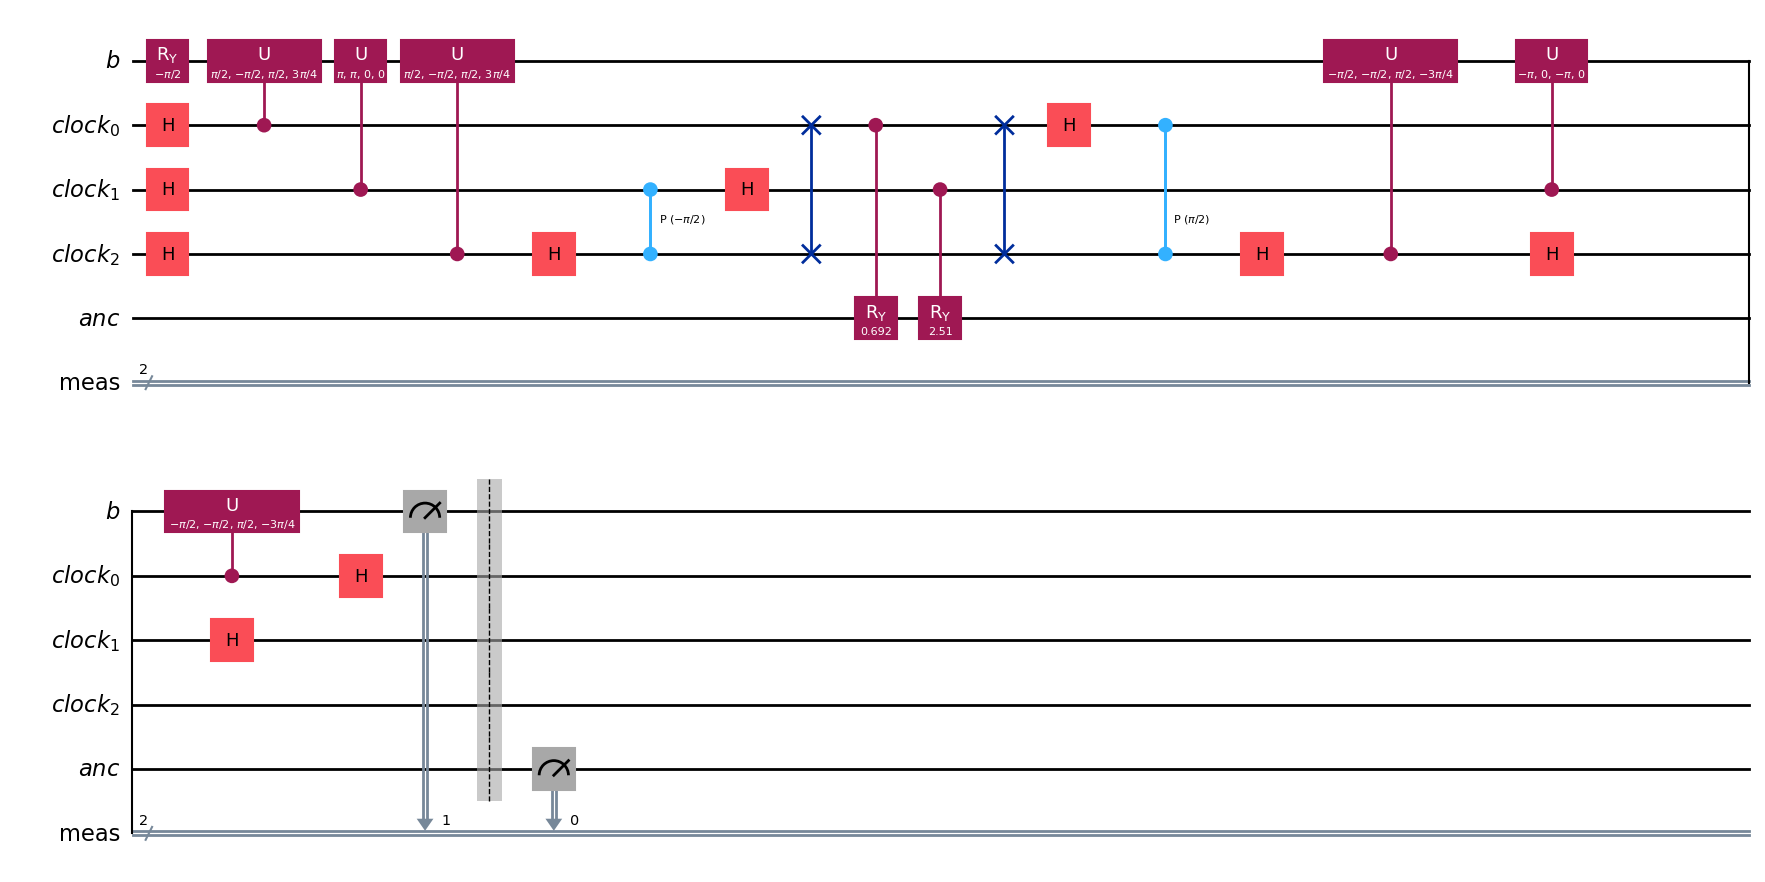

In [420]:
# --- 10) Construção do Circuito HHL ---
q_b = QuantumRegister(1, 'b')
q_clock = QuantumRegister(m_phase, 'clock')
q_anc = QuantumRegister(1, 'anc')
cl = ClassicalRegister(2, 'meas')

qc = QuantumCircuit(q_b, q_clock, q_anc, cl)

qc.ry(-np.pi / 2, q_b[0])

for j in range(m_phase):
    qc.h(q_clock[j])

angle_u0 = np.pi / 2
angle_u1 = -np.pi / 2
angle_u2 = np.pi / 2
angle_u3 = 3 * np.pi / 4

qc.cu(angle_u0, angle_u1, angle_u2, angle_u3, q_clock[0], q_b[0])
qc.cu(np.pi, np.pi, 0, 0, q_clock[1], q_b[0])
qc.cu(np.pi / 2, -np.pi / 2, np.pi / 2, 3 * np.pi / 4, q_clock[2], q_b[0])

C = 1.0

qc.h(q_clock[2])
qc.cp(-np.pi / 2, q_clock[1], q_clock[2])
qc.h(q_clock[1])
qc.swap(q_clock[0], q_clock[2])

theta_min = 2 * np.arcsin(C / max(abs(lambda_min), 1e-12))
theta_max = 2 * np.arcsin(C / max(abs(lambda_max), 1e-12))

qc.cry(theta_max, q_clock[0], q_anc[0])
qc.cry(theta_min, q_clock[1], q_anc[0])

qc.swap(q_clock[0], q_clock[2])
qc.h(q_clock[0])
qc.cp(np.pi / 2, q_clock[0], q_clock[2])
qc.h(q_clock[2])

cu_2_inv = CUGate(np.pi / 2, -np.pi / 2, np.pi / 2, 3 * np.pi / 4).inverse()
qc.append(cu_2_inv, [q_clock[2], q_b[0]])

cu_1_inv = CUGate(np.pi, np.pi, 0, 0).inverse()
qc.append(cu_1_inv, [q_clock[1], q_b[0]])

cu_0_inv = CUGate(angle_u0, angle_u1, angle_u2, angle_u3).inverse()
qc.append(cu_0_inv, [q_clock[0], q_b[0]])

for j in range(m_phase):
    qc.h(q_clock[j])

qc.measure(q_b[0], cl[1])
qc.barrier()
qc.measure(q_anc[0], cl[0])

qc.draw('mpl')

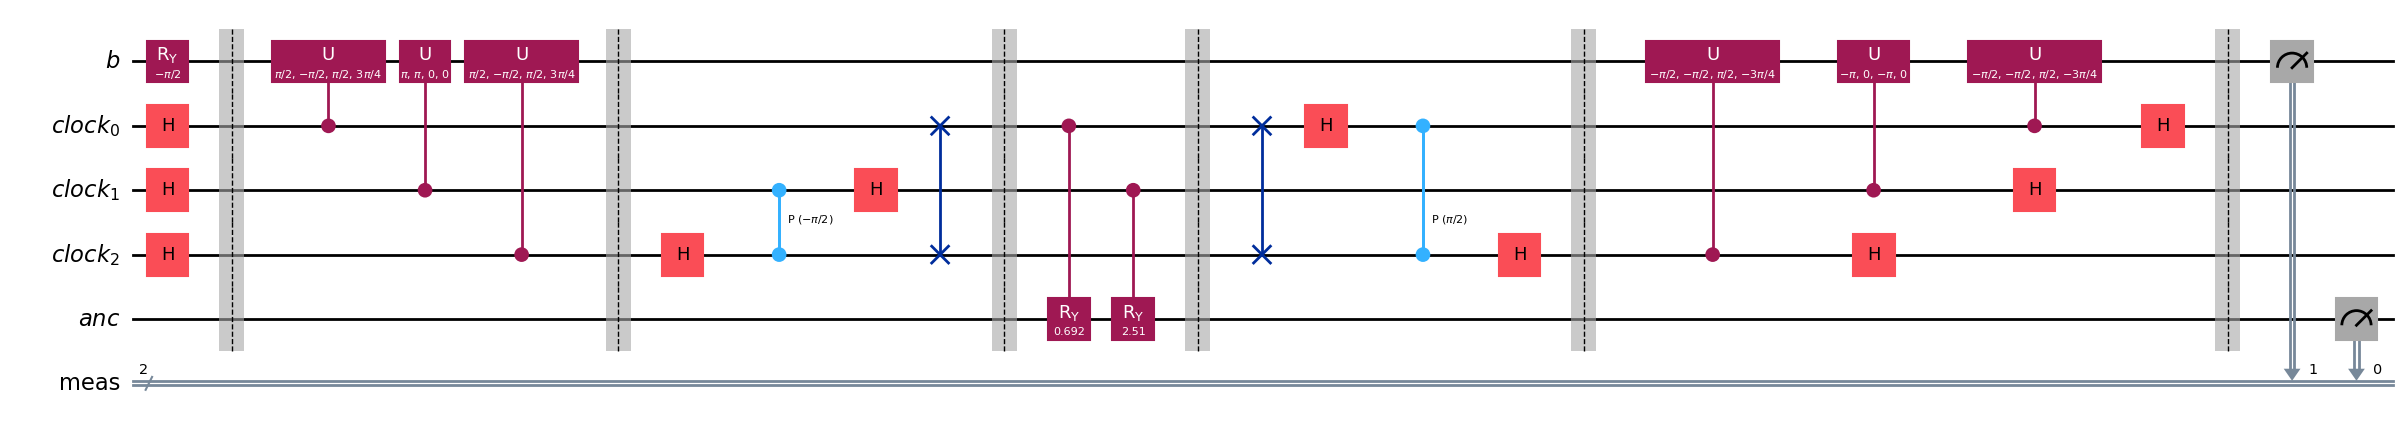

In [421]:
# --- 10) Construção do Circuito HHL ---
q_b = QuantumRegister(1, 'b')
q_clock = QuantumRegister(m_phase, 'clock')
q_anc = QuantumRegister(1, 'anc')
cl = ClassicalRegister(2, 'meas')

qc = QuantumCircuit(q_b, q_clock, q_anc, cl)

# 1. Preparação do Estado |b> e Superposição nos Clocks
qc.ry(-np.pi / 2, q_b[0])
for j in range(m_phase):
    qc.h(q_clock[j])

qc.barrier()  # --- FIM DA PREPARAÇÃO ---

# 2. QPE: Evolução Temporal Controlada (Phase Estimation)
angle_u0 = np.pi / 2
angle_u1 = -np.pi / 2
angle_u2 = np.pi / 2
angle_u3 = 3 * np.pi / 4

qc.cu(angle_u0, angle_u1, angle_u2, angle_u3, q_clock[0], q_b[0])
qc.cu(np.pi, np.pi, 0, 0, q_clock[1], q_b[0])
qc.cu(np.pi / 2, -np.pi / 2, np.pi / 2, 3 * np.pi / 4, q_clock[2], q_b[0])

qc.barrier()  # --- FIM DOS CU ---

# 3. IQFT (Transformada Inversa de Fourier Quântica)
qc.h(q_clock[2])
qc.cp(-np.pi / 2, q_clock[1], q_clock[2])
qc.h(q_clock[1])
qc.swap(q_clock[0], q_clock[2])

qc.barrier()  # --- FIM DA IQFT ---

# 4. Rotações Controladas na Ancilla (Eigenvalue Inversion)
C = 1.0
theta_min = 2 * np.arcsin(C / max(abs(lambda_min), 1e-12))
theta_max = 2 * np.arcsin(C / max(abs(lambda_max), 1e-12))

qc.cry(theta_max, q_clock[0], q_anc[0])
qc.cry(theta_min, q_clock[1], q_anc[0])

qc.barrier()  # --- FIM DA ROTAÇÃO CONTROLADA ---

# 5. QFT (Desfazer a Transformada de Fourier)
qc.swap(q_clock[0], q_clock[2])
qc.h(q_clock[0])
qc.cp(np.pi / 2, q_clock[0], q_clock[2])
qc.h(q_clock[2])

qc.barrier()  # --- FIM DA QFT ---

# 6. Uncomputation dos CU (Desfazer os CU)
cu_2_inv = CUGate(np.pi / 2, -np.pi / 2, np.pi / 2, 3 * np.pi / 4).inverse()
qc.append(cu_2_inv, [q_clock[2], q_b[0]])

cu_1_inv = CUGate(np.pi, np.pi, 0, 0).inverse()
qc.append(cu_1_inv, [q_clock[1], q_b[0]])

cu_0_inv = CUGate(angle_u0, angle_u1, angle_u2, angle_u3).inverse()
qc.append(cu_0_inv, [q_clock[0], q_b[0]])

for j in range(m_phase):
    qc.h(q_clock[j])

qc.barrier()  # --- FIM DO DESFAZIMENTO (UNCOMPUTATION) ---

# 7. Medições
qc.measure(q_b[0], cl[1])
qc.measure(q_anc[0], cl[0])

# Desenhar com opção para não achatar ou quebrar de forma confusa
qc.draw('mpl', fold=-1)  # 'fold=-1' evita que o Qiskit dobre o circuito em várias linhas se for muito longo

In [422]:
fig = qc.draw('mpl', fold=-1)
fig.savefig('circuito_hhl.png', dpi=300, bbox_inches='tight')

Total de medições de sucesso (Ancilla = 1): 2231 de 4096 shots
Vetor Quântico Extraído (a): [ 0.70408935 -0.71011139]


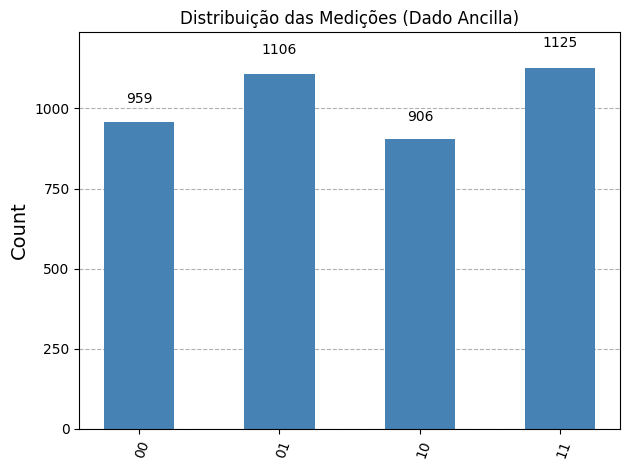

In [423]:


# --- 11) Simulação e Extração Matemática do Vetor ---
sim = AerSimulator()
job = sim.run(qc, shots=4096)
counts = job.result().get_counts()

prob_01 = counts.get('01', 0)
prob_11 = counts.get('11', 0)
total_sucesso = prob_01 + prob_11

if total_sucesso > 0:
    a_0 = np.sqrt(prob_01 / total_sucesso)
    a_1 = -np.sqrt(prob_11 / total_sucesso)
    alpha_quanto = np.array([a_0, a_1])
else:
    alpha_quanto = np.array([0, 0])

print(f"Total de medições de sucesso (Ancilla = 1): {total_sucesso} de 4096 shots")
print(f"Vetor Quântico Extraído (a): {alpha_quanto}")

# distribuição dos estados
plot_histogram(counts, title="Distribuição das Medições (Dado Ancilla)", color="steelblue")

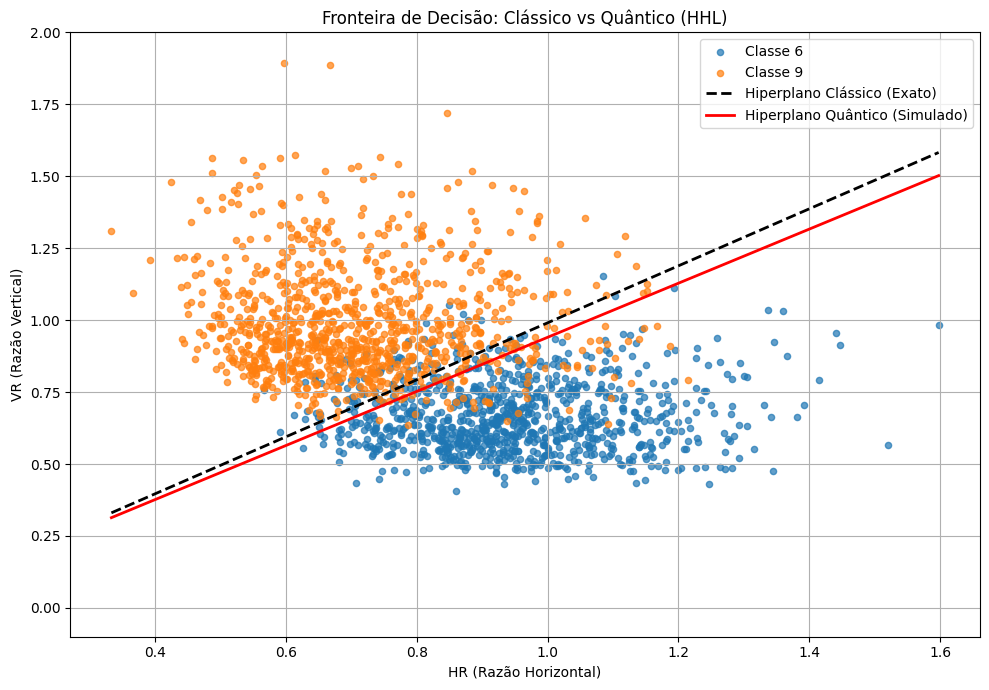

Acurácia Clássica (Gabarito): 90.85%
Acurácia Quântica (HHL Simulado): 90.85%

alpha clássica:
[ 1.98157153 -1.98157153]
alpha quântico (HHL): [ 0.70408935 -0.71011139]


In [424]:
# --- 12) Avaliação das Fronteiras ---
alpha_classica = np.linalg.solve(A_hat, y_hat)

w_classico = alpha_classica[0] * x0 + alpha_classica[1] * x1
w_quanto = alpha_quanto[0] * x0 + alpha_quanto[1] * x1

df_teste['f_classico'] = w_classico[0] * df_teste['HR'] + w_classico[1] * df_teste['VR']
df_teste['y_pred_classico'] = np.where(df_teste['f_classico'] > 0, 1, -1)

df_teste['f_quanto'] = w_quanto[0] * df_teste['HR'] + w_quanto[1] * df_teste['VR']
df_teste['y_pred_quanto'] = np.where(df_teste['f_quanto'] > 0, 1, -1)

hr_vals = np.linspace(df_teste['HR'].min(), df_teste['HR'].max(), 200)

vr_vals_classico = -(w_classico[0] / w_classico[1]) * hr_vals if abs(w_classico[1]) > 1e-12 else np.zeros_like(hr_vals)
vr_vals_quanto = -(w_quanto[0] / w_quanto[1]) * hr_vals if abs(w_quanto[1]) > 1e-12 else np.zeros_like(hr_vals)

fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(df_teste[df_teste['y_real'] == 1]['HR'], df_teste[df_teste['y_real'] == 1]['VR'], s=20, alpha=0.7, color='tab:blue', label='Classe 6')
ax.scatter(df_teste[df_teste['y_real'] == -1]['HR'], df_teste[df_teste['y_real'] == -1]['VR'], s=20, alpha=0.7, color='tab:orange', label='Classe 9')
ax.plot(hr_vals, vr_vals_classico, color='black', linestyle='--', linewidth=2, label='Hiperplano Clássico (Exato)')
ax.plot(hr_vals, vr_vals_quanto, color='red', linestyle='-', linewidth=2, label='Hiperplano Quântico (Simulado)')
ax.set_title("Fronteira de Decisão: Clássico vs Quântico (HHL)")
ax.set_xlabel("HR (Razão Horizontal)")
ax.set_ylabel("VR (Razão Vertical)")
ax.set_ylim(-0.1, 2.0)
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

acuracia_classica = (df_teste['y_real'] == df_teste['y_pred_classico']).mean() * 100
acuracia_quantica = (df_teste['y_real'] == df_teste['y_pred_quanto']).mean() * 100

print(f"Acurácia Clássica (Gabarito): {acuracia_classica:.2f}%")
print(f"Acurácia Quântica (HHL Simulado): {acuracia_quantica:.2f}%")
alpha_classica = np.linalg.solve(A_hat, y_hat)
print("\nalpha clássica:")
print(alpha_classica)
print(f"alpha quântico (HHL): {alpha_quanto}")

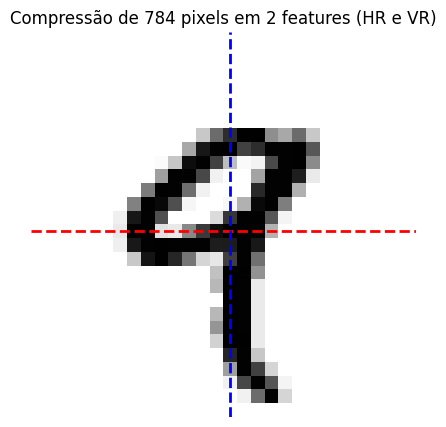

In [425]:
exemplo_pixels = treino_9.iloc[0, 1:].values
img_exemplo = exemplo_pixels.reshape(28, 28)

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(img_exemplo, cmap='gray_r')

ax.axhline(y=14, color='red', linestyle='--', linewidth=2)
ax.axvline(x=14, color='blue', linestyle='--', linewidth=2)

ax.set_title("Compressão de 784 pixels em 2 features (HR e VR)")
ax.axis('off')
plt.show()




<>:18: SyntaxWarning: invalid escape sequence '\l'
<>:18: SyntaxWarning: invalid escape sequence '\l'
C:\Users\Thierry\AppData\Local\Temp\ipykernel_18468\775104152.py:18: SyntaxWarning: invalid escape sequence '\l'
  ax.plot(N, tempo_quantum_ideal, color='tab:blue', linewidth=3, label='HHL Ideal $O(\log N)$')


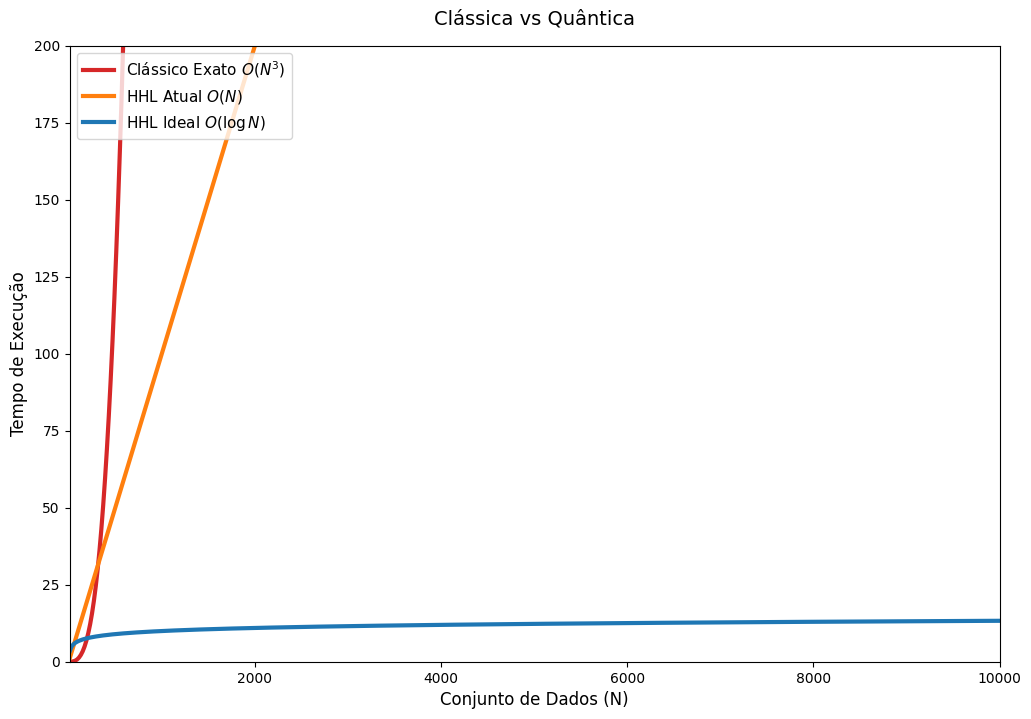

In [ ]:
# Tamanhos da matriz N 
N = np.linspace(10, 10000, 500)

# 1. Complexidade Clássica (O(N^3)
tempo_classico = (N / 100)**3 

# 2. Complexidade Quântica O(log N)
tempo_quantum_ideal = np.log2(N)

# 3. HHL atual com interferência O(N)
tempo_quantum_nisq = N / 10

# Configuração do gráfico
fig, ax = plt.subplots(figsize=(12, 8))

ax.plot(N, tempo_classico, color='tab:red', linewidth=3, label='Clássico Exato $O(N^3)$')
ax.plot(N, tempo_quantum_nisq, color='tab:orange', linewidth=3, label='HHL Atual $O(N)$')
ax.plot(N, tempo_quantum_ideal, color='tab:blue', linewidth=3, label='HHL Ideal $O(\log N)$')

ax.set_ylim(0, 200)
ax.set_xlim(10, 10000)
ax.set_title("Clássica vs Quântica", fontsize=14, pad=15)
ax.set_xlabel("Conjunto de Dados (N)", fontsize=12)
ax.set_ylabel("Tempo de Execução", fontsize=12)

ax.legend(fontsize=11, loc='upper left')

#plt.tight_layout()
plt.show()

<>:20: SyntaxWarning: invalid escape sequence '\m'
<>:21: SyntaxWarning: invalid escape sequence '\m'
<>:22: SyntaxWarning: invalid escape sequence '\m'
<>:20: SyntaxWarning: invalid escape sequence '\m'
<>:21: SyntaxWarning: invalid escape sequence '\m'
<>:22: SyntaxWarning: invalid escape sequence '\m'
C:\Users\Thierry\AppData\Local\Temp\ipykernel_18468\852291782.py:20: SyntaxWarning: invalid escape sequence '\m'
  ax.plot(N, tempo_classico, color='tab:red', linewidth=3, label='Clássico Exato $\mathcal{O}(N^3)$')
C:\Users\Thierry\AppData\Local\Temp\ipykernel_18468\852291782.py:21: SyntaxWarning: invalid escape sequence '\m'
  ax.plot(N, tempo_quantum_nisq, color='tab:orange', linewidth=3, label='HHL Atual $\mathcal{O}(N)$')
C:\Users\Thierry\AppData\Local\Temp\ipykernel_18468\852291782.py:22: SyntaxWarning: invalid escape sequence '\m'
  ax.plot(N, tempo_quantum_ideal, color='tab:blue', linewidth=3, label='HHL Ideal $\mathcal{O}(\log N)$')


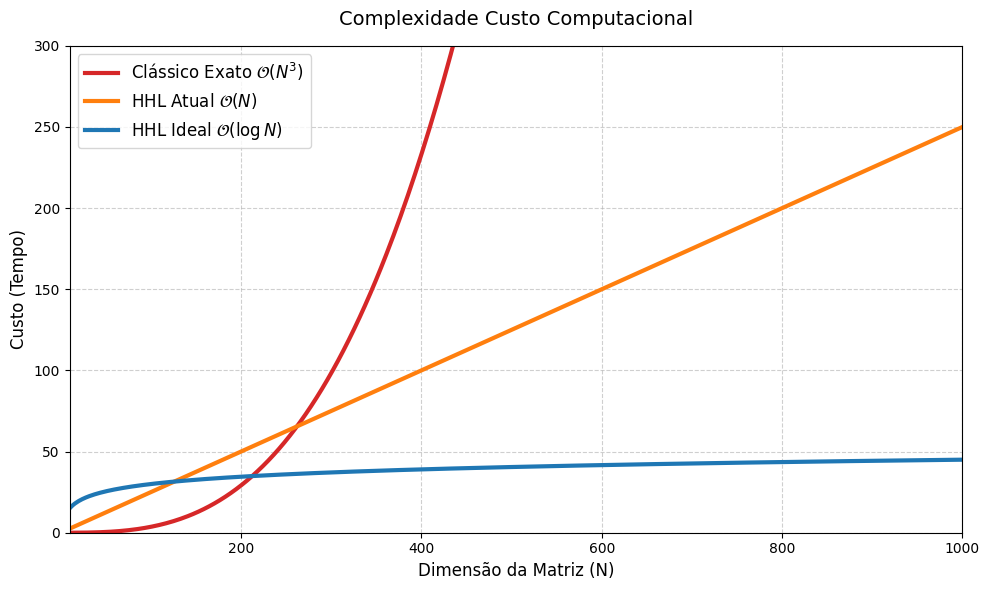

In [431]:
import numpy as np
import matplotlib.pyplot as plt

# Tamanho do Dataset N (Reduzido para 1000 para focar na zona de cruzamento)
N = np.linspace(10, 1000, 500)

# Ajuste dos fatores de escala para contar a "história" visual:
# 1. Complexidade Clássica O(N^3)
tempo_classico = (N / 65)**3 

# 2. HHL atual (NISQ) O(N)
tempo_quantum_nisq = N / 4

# 3. Complexidade Quântica Ideal O(log N)
tempo_quantum_ideal = 15 * np.log10(N)

# Configuração do gráfico
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(N, tempo_classico, color='tab:red', linewidth=3, label='Clássico Exato $\mathcal{O}(N^3)$')
ax.plot(N, tempo_quantum_nisq, color='tab:orange', linewidth=3, label='HHL Atual $\mathcal{O}(N)$')
ax.plot(N, tempo_quantum_ideal, color='tab:blue', linewidth=3, label='HHL Ideal $\mathcal{O}(\log N)$')

# Ajuste dos limites para emoldurar a explosão da curva vermelha
ax.set_ylim(0, 300)
ax.set_xlim(10, 1000)

# Títulos e labels mais formais
ax.set_title("Complexidade Custo Computacional", fontsize=14, pad=15)
ax.set_xlabel("Dimensão da Matriz (N)", fontsize=12)
ax.set_ylabel("Custo (Tempo)", fontsize=12)

ax.legend(fontsize=12, loc='upper left')

# Uma grade leve ajuda muito na leitura de gráficos em pôsteres
ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

Matriz das características HR e VR:
[[0.93258191 0.66401088]
 [0.72993114 1.00486868]]


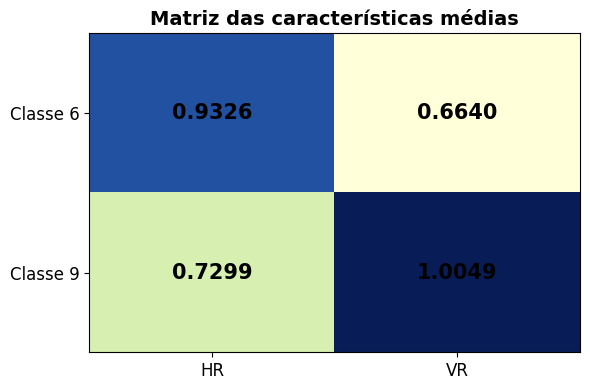

In [427]:
# Matriz das características médias das classes
matriz_hr_vr = np.array([
    [HR_medio_6, VR_medio_6],
    [HR_medio_9, VR_medio_9]
])

print("Matriz das características HR e VR:")
print(matriz_hr_vr)

fig, ax = plt.subplots(figsize=(6, 4))

imagem = ax.imshow(
    matriz_hr_vr,
    cmap="YlGnBu",
    aspect="auto"
)

# Valores dentro das células
for linha in range(matriz_hr_vr.shape[0]):
    for coluna in range(matriz_hr_vr.shape[1]):
        ax.text(
            coluna,
            linha,
            f"{matriz_hr_vr[linha, coluna]:.4f}",
            ha="center",
            va="center",
            fontsize=15,
            fontweight="bold",
            color="black"
        )

ax.set_xticks([0, 1])
ax.set_xticklabels(["HR", "VR"], fontsize=12)

ax.set_yticks([0, 1])
ax.set_yticklabels(["Classe 6", "Classe 9"], fontsize=12)

ax.set_title(
    "Matriz das características médias",
    fontsize=14,
    fontweight="bold"
)


plt.tight_layout()
plt.show()